## Map seam detection
Searching the satellite reference map for geometric seams (local stitching offsets)
- Runway features are straight, so each long linear feature should be a straight line in the map
- Rotate runway to horizontal, track each feature's cross-track position y(s) per column, fit a robust line, inspect residual r(s)
- A seam = step in r(s) at the SAME along-track position s across several features

Simplifications (stated up front)
- Google Earth screenshot: no georeferencing or seamline metadata
- Pixel scale taken from the 60 m scale bar (approx)
- Every feature is treated as an edge (signed y-gradient peak) - a painted line is two edges (rising + falling)

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import warnings
from scipy.signal import find_peaks

%matplotlib inline

Image (H, W): (1239, 1783)  approx m/px: 0.185


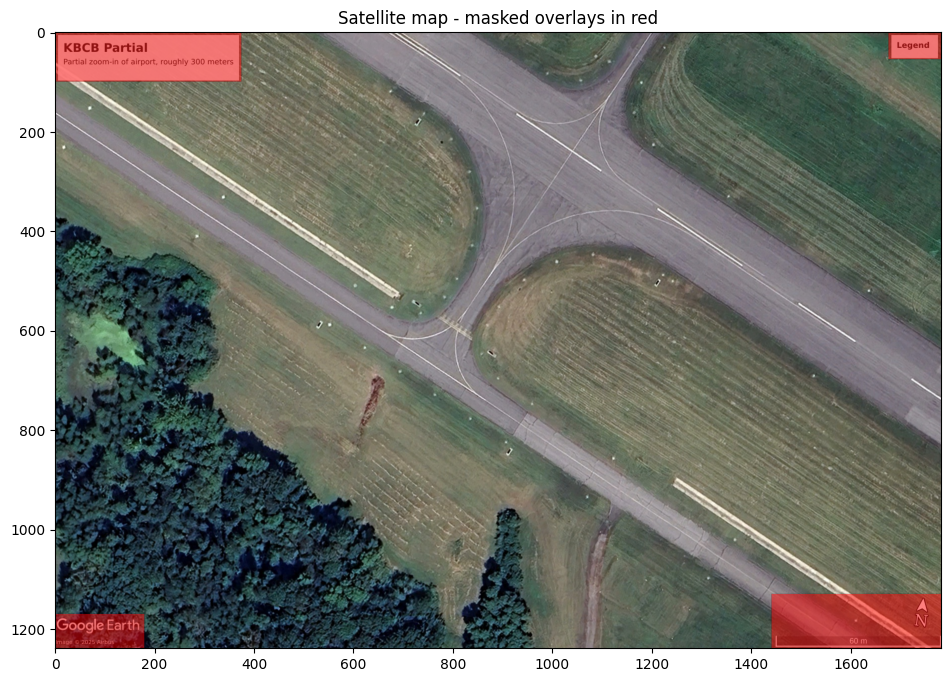

In [2]:
# Satellite reference image
sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery

# SIMPLIFICATION: 60 m scale bar is ~325 px wide in this screenshot -> approx scale
M_PER_PX = 60 / 325

im_bgr = cv2.imread(sat_ref)
im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64) / 255.0
H, W = gray.shape
print("Image (H, W):", (H, W), " approx m/px:", round(M_PER_PX, 3))

# Overlay boxes to mask (x0, y0, x1, y1) 
overlays = {'title': (0, 0, 375, 100),
            'legend': (1675, 0, 1783, 55),
            'logo': (0, 1170, 180, 1239),
            'scale_north': (1440, 1130, 1783, 1239)}
mask = np.ones((H, W), np.uint8)
for x0, y0, x1, y1 in overlays.values():
    mask[y0:y1, x0:x1] = 0

plt.figure(figsize=(12, 8))
plt.imshow(im_rgb)
plt.imshow(np.ma.masked_where(mask > 0, mask), cmap='autumn', alpha=0.5)
plt.title("Satellite map - masked overlays in red")
plt.show()

### Step 1: rotate runway to horizontal
- Canny turns grayscale image into edge map 
- Hough lines find straight segments in the edge map 
- Median angle of long egdes (over 600 pixels), keep all those within 2 degrees
- Average angle kept by weight
- Rotate full image about center so lane lines are across image

Lines kept: 17/29   runway angle: 33.740 deg


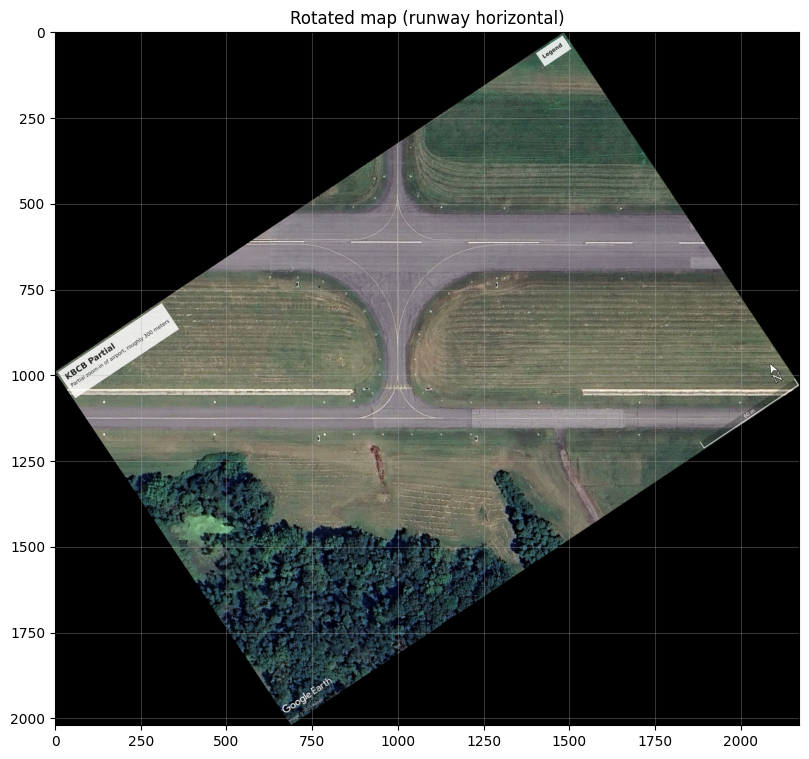

In [3]:
# Runway direction from long Hough lines
edges = cv2.Canny((gray * 255).astype(np.uint8), 50, 150)
edges[mask == 0] = 0
lines = cv2.HoughLinesP(edges, 1, np.pi / 720, 200, minLineLength=300, maxLineGap=10)[:, 0]
ang = np.degrees(np.arctan2(lines[:, 3] - lines[:, 1], lines[:, 2] - lines[:, 0]))
length = np.hypot(lines[:, 2] - lines[:, 0], lines[:, 3] - lines[:, 1])

# Dominant direction = median of the longest lines (runway / taxiway edges); keep lines within 2 deg of it
mode = np.median(ang[length > 600])
keep = np.abs(ang - mode) < 2
theta_deg = np.average(ang[keep], weights=length[keep])
print(f"Lines kept: {keep.sum()}/{len(ang)}   runway angle: {theta_deg:.3f} deg")

def rotate_keep_all(img, theta_deg, interp):
    """
    Rotate image by theta_deg (CCW) on an expanded canvas so nothing is cropped
    Output: rotated image, 2x3 affine used
    """
    h, w = img.shape[:2]
    R = cv2.getRotationMatrix2D((w / 2, h / 2), theta_deg, 1.0)
    c, s = abs(R[0, 0]), abs(R[0, 1])
    nw, nh = int(np.ceil(h * s + w * c)), int(np.ceil(h * c + w * s))
    R[0, 2] += nw / 2 - w / 2
    R[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, R, (nw, nh), flags=interp, borderValue=0), R

gray_r, R_rot = rotate_keep_all(gray, theta_deg, cv2.INTER_CUBIC)
rgb_r, _ = rotate_keep_all(im_rgb, theta_deg, cv2.INTER_CUBIC)
mask_r, _ = rotate_keep_all(mask, theta_deg, cv2.INTER_NEAREST)
# Erode so the Sobel kernel never touches the canvas border / masked boxes
mask_r = cv2.erode(mask_r, np.ones((9, 9), np.uint8))

plt.figure(figsize=(14, 9))
plt.imshow(rgb_r)
plt.grid(alpha=0.3)
plt.title("Rotated map (runway horizontal)")
plt.show()

### Step 2: line position y(s) per column
**2a. Find the features.** 
- Find average gradient along each row - rows with few valid pixels are ignored (row profile)
- Find peaks in row profile - rows with the BIGGEST values - best features (8 biggest) 
- Also keep direction 



F0 row  383  polarity +1  mean grad +0.1868
F1 row  450  polarity -1  mean grad -0.1453
F2 row  532  polarity +1  mean grad +0.1794
F3 row  611  polarity +1  mean grad +0.4212
F4 row 1041  polarity +1  mean grad +0.6874
F5 row 1058  polarity -1  mean grad -0.5260
F6 row 1127  polarity -1  mean grad -0.5999
F7 row 1153  polarity -1  mean grad -0.1640


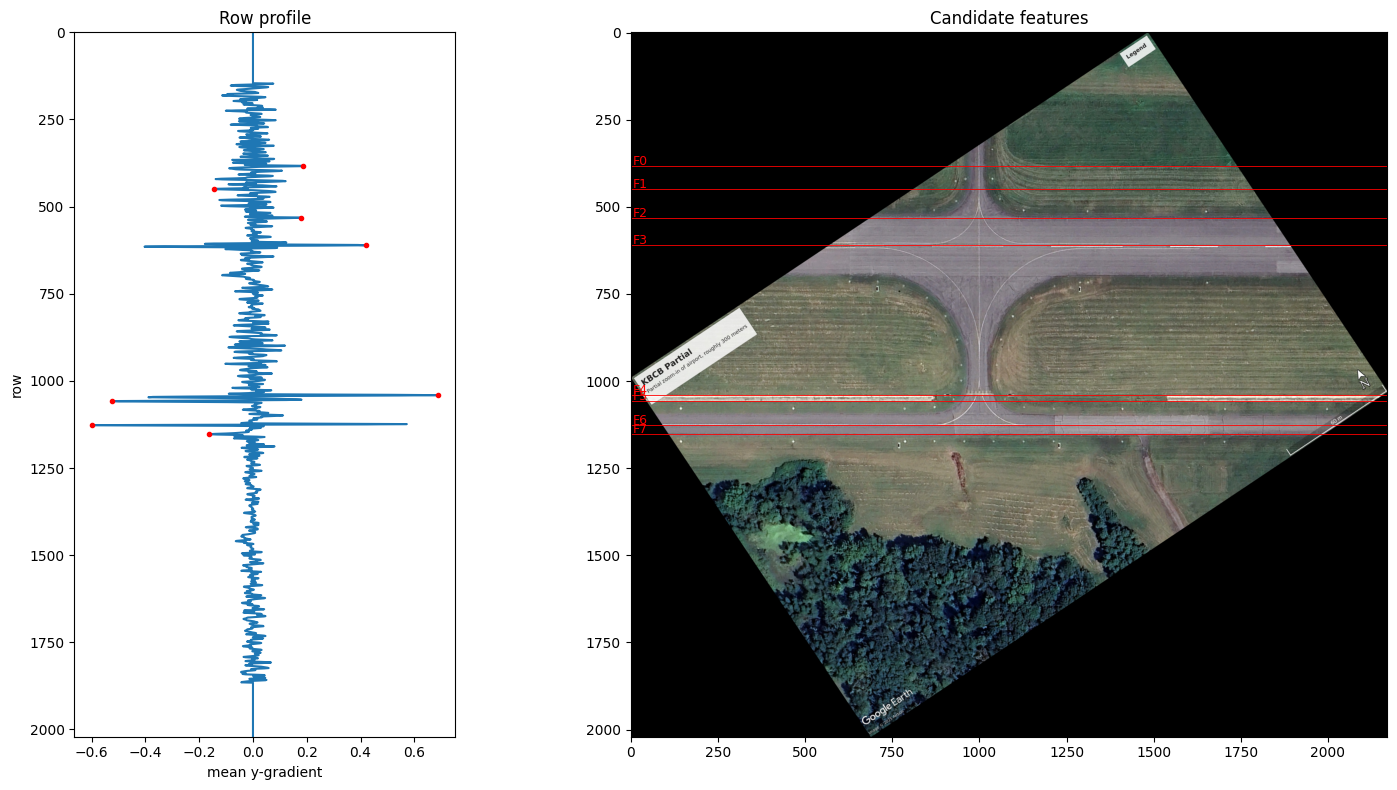

In [4]:
# Signed vertical gradient on the rotated map (light blur to suppress JPEG noise)
g_blur = cv2.GaussianBlur(gray_r, (0, 0), 1.0)
gy = cv2.Sobel(g_blur, cv2.CV_64F, 0, 1, ksize=3)
gy[mask_r == 0] = np.nan

# Row profile: mean signed gradient per row (rows with few valid px ignored)
MIN_ROW_PX = 300
n_valid = np.isfinite(gy).sum(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    row_prof = np.nanmean(gy, axis=1)
row_prof[n_valid < MIN_ROW_PX] = 0

# Candidate features: strongest N_FEAT peaks of |row profile|
N_FEAT = 8
BAND_HALF = 6 # band = row +- BAND_HALF px
pk, props = find_peaks(np.abs(row_prof), distance=2 * BAND_HALF + 1, prominence=0)
pk_top = np.sort(pk[np.argsort(np.abs(row_prof[pk]))[::-1][:N_FEAT]])
feats = {f'F{i}': {'row': int(r), 'pol': np.sign(row_prof[r])} for i, r in enumerate(pk_top)}
for k, f in feats.items():
    print(k, f"row {f['row']:4d}  polarity {f['pol']:+.0f}  mean grad {row_prof[f['row']]:+.4f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={'width_ratios': [1, 3]})
ax[0].plot(row_prof, np.arange(len(row_prof)))
ax[0].plot(row_prof[pk_top], pk_top, 'r.')
ax[0].set_ylim(gray_r.shape[0], 0) # same row range as the rotated image (row 0 at top)
ax[0].set_xlabel('mean y-gradient'); ax[0].set_ylabel('row')
ax[0].set_title('Row profile')
ax[1].imshow(rgb_r)
for k, f in feats.items():
    ax[1].axhline(f['row'], color='r', lw=0.6)
    ax[1].text(5, f['row'] - 3, k, color='r', fontsize=9)
ax[1].set_title('Candidate features')
plt.tight_layout(); plt.show()

**2b. Track each feature.** 
- Consider band of pixels plus/minus 6 rows from the 8 peak rows
- Feature is the STRONGEST gradient
- If the gradient jumps several rows, potentially a PEAK
- Draw curve through 3 pixels, take the top of the curve
- Remove bad columns (breaks in centerlines)

In a narrow band around its row, per column
- Argmax of (polarity x gradient), then parabola sub-pixel refinement: `dy = (g- - g+) / (2(g- - 2g0 + g+))`
- Drop weak columns (dash gaps, taxiway crossing, markers), then median-bin a few columns

/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp
/tmp/ipykernel_153733/966789251.py:20: RuntimeWarning: invalid value encountered in subtract
  denom = gm - 2 * g0 + gp


F0 coverage  29.5% of bins
F1 coverage  32.9% of bins
F2 coverage  48.2% of bins
F3 coverage  34.8% of bins
F4 coverage  55.3% of bins
F5 coverage  55.3% of bins
F6 coverage  71.7% of bins
F7 coverage  77.2% of bins


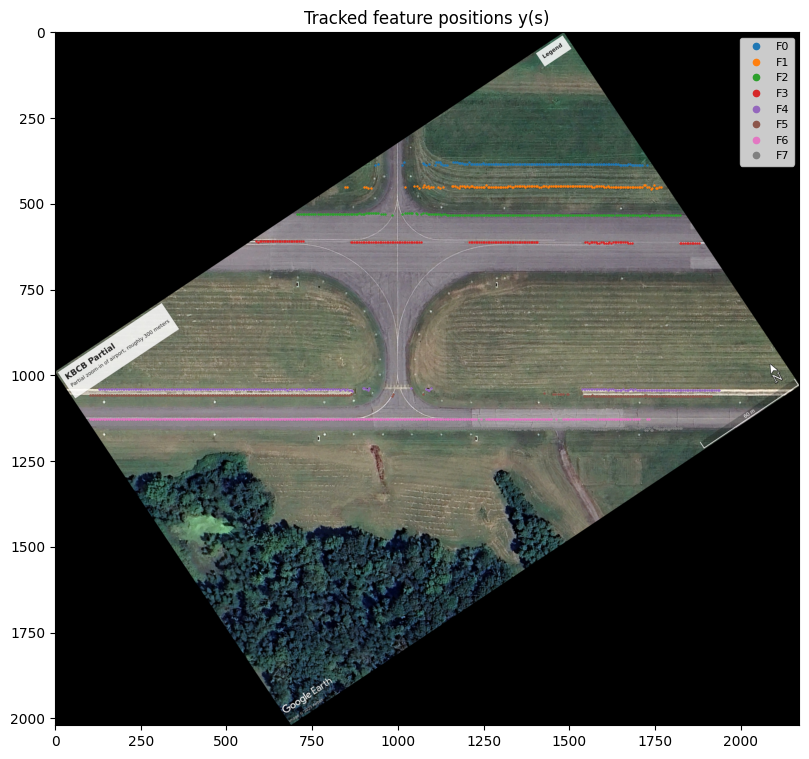

In [5]:
MIN_REL = 0.3 # column kept if its peak gradient > MIN_REL x median peak of that feature
BIN_W = 5     # columns per bin

def extract_profile(gy, mask_r, row, pol, band_half=BAND_HALF, min_rel=MIN_REL):
    """
    Sub-pixel cross-track position of one feature in every column
    Input: signed gradient, rotated mask, feature row, polarity (+1/-1)
    Output: y per column (nan where invalid), peak strength per column
    """
    lo, hi = row - band_half, row + band_half + 1
    band = pol * gy[lo:hi, :] # flip so the feature is a positive peak
    valid_col = (mask_r[lo:hi, :] > 0).all(axis=0)
    band_f = np.where(np.isfinite(band), band, -np.inf)
    k = np.argmax(band_f, axis=0)
    cols = np.arange(band.shape[1])
    inner = (k > 0) & (k < band.shape[0] - 1) # peak on band edge -> no parabola, drop
    g0 = band_f[k, cols]
    gm = band_f[np.clip(k - 1, 0, None), cols]
    gp = band_f[np.clip(k + 1, None, band.shape[0] - 1), cols]
    denom = gm - 2 * g0 + gp
    with np.errstate(invalid='ignore', divide='ignore'):
        dy = np.where(inner & (denom < 0), 0.5 * (gm - gp) / denom, np.nan)
    y = lo + k + dy
    ok = valid_col & np.isfinite(dy) & (g0 > 0)
    if ok.sum() == 0:
        return np.full(len(cols), np.nan), g0
    ok &= g0 > min_rel * np.median(g0[ok])
    y[~ok] = np.nan
    return y, g0

def bin_profile(y, bin_w=BIN_W, min_valid=3):
    """
    Median of y over bins of bin_w columns (bin needs >= min_valid valid columns)
    Output: bin center s (px), binned y
    """
    n = len(y) // bin_w
    yb = y[:n * bin_w].reshape(n, bin_w)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        ym = np.nanmedian(yb, axis=1)
    ym[np.isfinite(yb).sum(axis=1) < min_valid] = np.nan
    s = np.arange(n) * bin_w + (bin_w - 1) / 2
    return s, ym

for k, f in feats.items():
    y_col, _ = extract_profile(gy, mask_r, f['row'], f['pol'])
    f['s'], f['y'] = bin_profile(y_col)
    print(k, f"coverage {np.isfinite(f['y']).mean() * 100:5.1f}% of bins")

# Overlay tracked points
plt.figure(figsize=(14, 9))
plt.imshow(rgb_r)
for k, f in feats.items():
    plt.plot(f['s'], f['y'], '.', ms=1.5, label=k)
plt.legend(markerscale=6, fontsize=8)
plt.title("Tracked feature positions y(s)")
plt.show()

### Step 3: robust straight-line fit and residual
- A feature without a seam should lie on a straight line
- Fit best straight line to each features points (ransac line fit)
- Subtract line from points, how far each point is off the line
- No seam means residual is just noise - seam shows a jump

feat    row  cover%  inlier%  resid ang(deg)  sigma px  sigma cm
F0      383    29.5     78.1          0.3141     0.632     11.66
F1      450    32.9     64.3         -0.0188     1.155     21.33
F2      532    48.2     83.7          0.2127     0.755     13.94
F3      611    34.8    100.0          0.1851     0.220      4.06
F4     1041    55.3     97.5          0.0438     0.254      4.70
F5     1058    55.3     94.6          0.0660     0.298      5.50
F6     1127    71.7    100.0          0.0315     0.262      4.84
F7     1153    77.2     55.2          0.2489     1.350     24.92


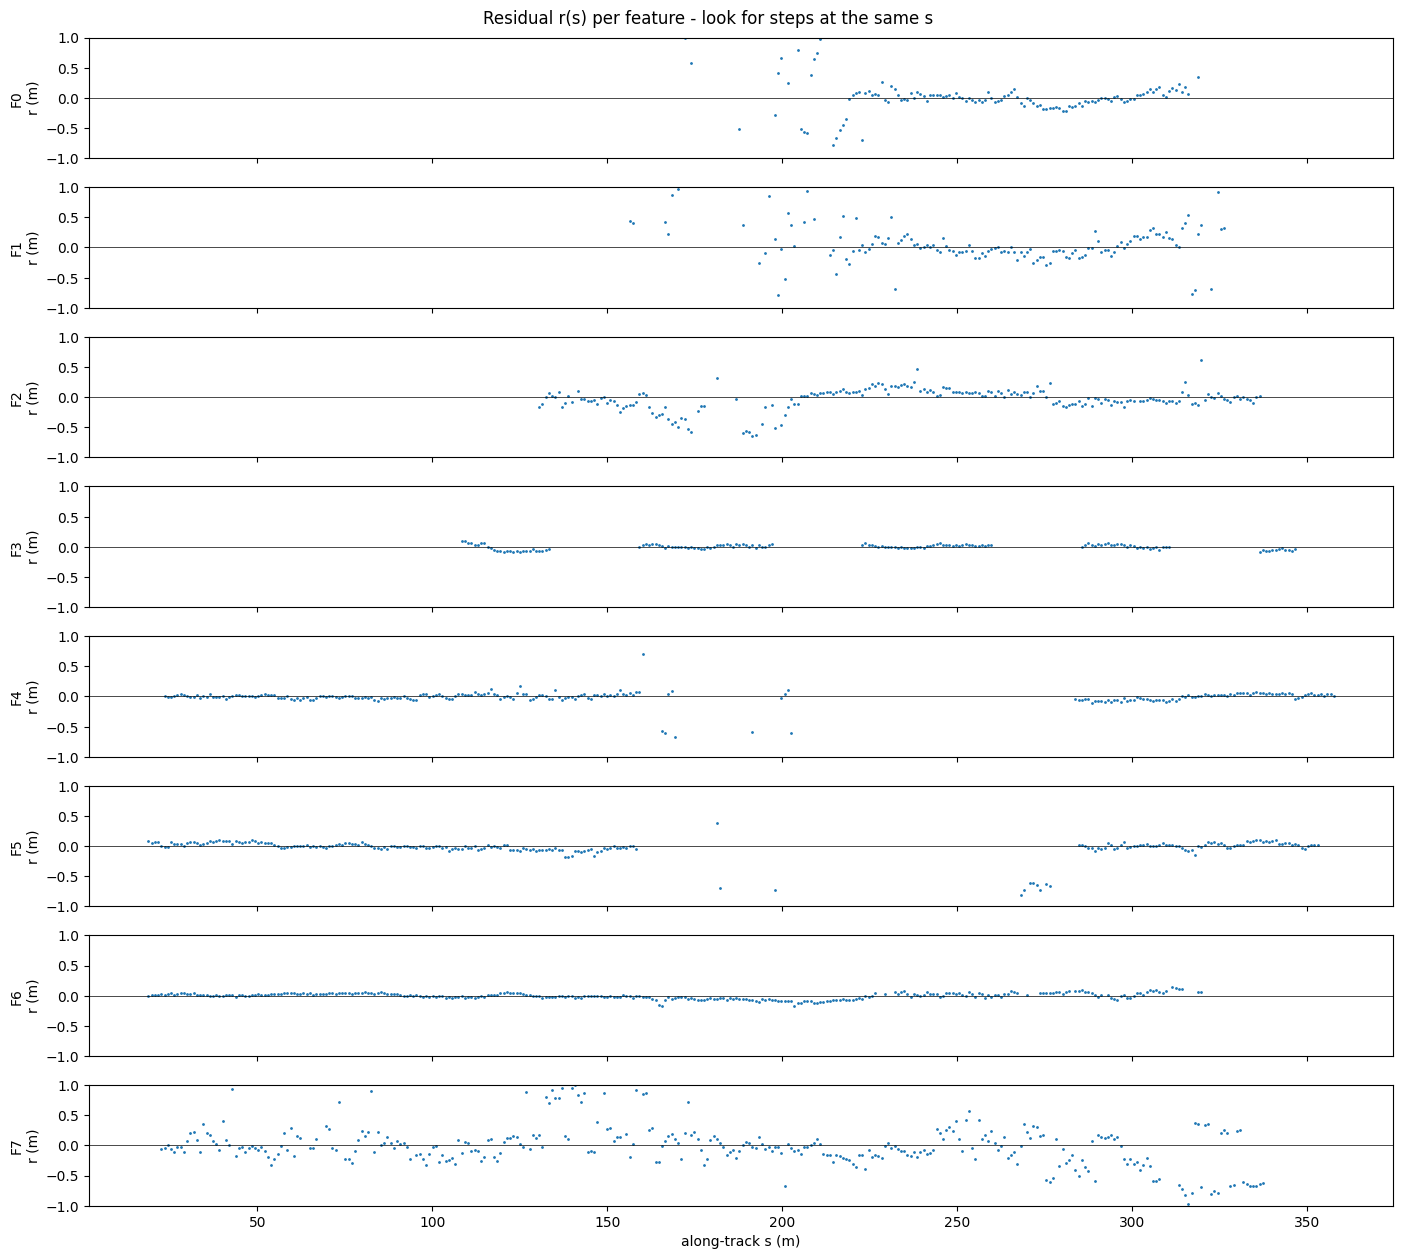

In [6]:
RANSAC_THRESH = 1.0 # px inlier threshold

def ransac_line_fit(s, y, thresh=RANSAC_THRESH, n_iter=1000, seed=0):
    """
    Robust line y = a + b s
    Output: a, b, inlier fraction
    """
    ok = np.isfinite(y)
    ss, yy = s[ok], y[ok]
    rng = np.random.default_rng(seed)
    best = np.zeros(len(ss), bool)
    for _ in range(n_iter):
        i, j = rng.choice(len(ss), 2, replace=False)
        if ss[i] == ss[j]:
            continue
        b = (yy[j] - yy[i]) / (ss[j] - ss[i])
        a = yy[i] - b * ss[i]
        inl = np.abs(yy - (a + b * ss)) < thresh
        if inl.sum() > best.sum():
            best = inl
    b, a = np.polyfit(ss[best], yy[best], 1)
    return a, b, best.mean()

print(f"{'feat':5s} {'row':>5s} {'cover%':>7s} {'inlier%':>8s} {'resid ang(deg)':>15s} {'sigma px':>9s} {'sigma cm':>9s}")
for k, f in feats.items():
    if np.isfinite(f['y']).sum() < 20:
        print(k, "too few points, skipped")
        continue
    a, b, inl = ransac_line_fit(f['s'], f['y'])
    f['r'] = f['y'] - (a + b * f['s'])
    rr = f['r'][np.isfinite(f['r'])]
    f['sigma'] = 1.4826 * np.median(np.abs(rr - np.median(rr)))
    print(f"{k:5s} {f['row']:5d} {np.isfinite(f['y']).mean() * 100:7.1f} {inl * 100:8.1f} "
          f"{np.degrees(np.arctan(b)):15.4f} {f['sigma']:9.3f} {f['sigma'] * M_PER_PX * 100:9.2f}")

# Stacked residuals (m), shared along-track axis
fit_feats = {k: f for k, f in feats.items() if 'r' in f}
fig, axs = plt.subplots(len(fit_feats), 1, figsize=(14, 1.6 * len(fit_feats)), sharex=True)
for ax, (k, f) in zip(np.atleast_1d(axs), fit_feats.items()):
    ax.plot(f['s'] * M_PER_PX, f['r'] * M_PER_PX, '.', ms=2)
    ax.axhline(0, color='k', lw=0.5)
    ax.set_ylim(-1, 1)
    ax.set_ylabel(f"{k}\nr (m)")
np.atleast_1d(axs)[-1].set_xlabel('along-track s (m)')
fig.suptitle('Residual r(s) per feature - look for steps at the same s')
plt.tight_layout(); plt.show()

### Step 4: change-point (step) test per feature
- Slide a candidate break s0 along each feature, fit `y = a + b s + d [s >= s0]` (line + step of size d)
- Score each s0 with z = |d| / SE(d); best s0 = most step-like location
- Outliers (> 4 sigma from step 3 residual) dropped first so isolated clusters don't fake a step

Simplifications
- Neighboring bins are correlated (blur, JPEG, binning), so z is inflated - Z_REF = 5 is a visual reference, not a calibrated threshold (step 5 cross-feature agreement is the real test)
- A step across a gap (dash gaps, taxiway crossing) is only located somewhere within that gap
- One step per feature (best s0 only)

feat      n  dropped  best s0 (m)  step d (cm)       z
F0      112       16        300.8        23.04     6.2
F1      135        8        288.8        28.06     4.2
F2      202        7        204.8        37.60    12.2
F3      151        0        300.8        -7.42     7.2
F4      234        6        313.8         7.66     8.5
F5      227       13         83.0        -9.21    11.1
F6      311        0        226.1        12.57    17.4
F7      327        8        120.8        45.33     7.8


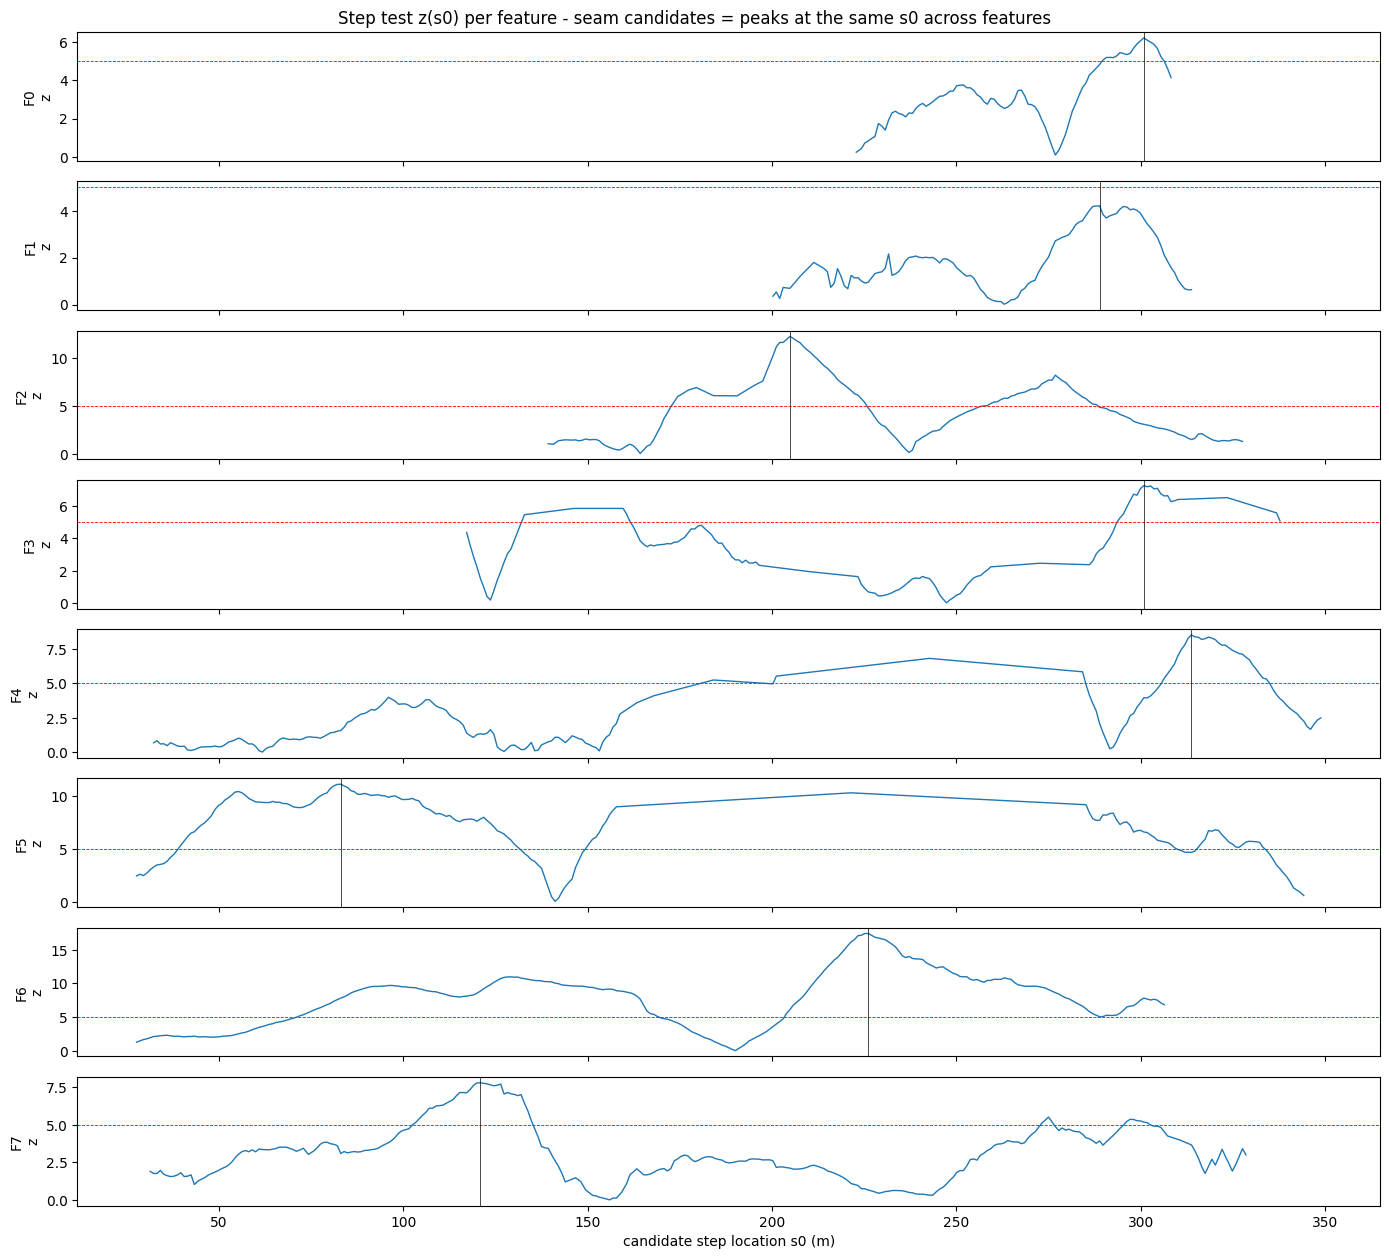

In [7]:
MIN_SEG = 10 # min bins on each side of a candidate step
OUT_K = 4    # drop points with |r| > OUT_K x sigma before the scan (e.g. F5 cluster near s~270 m)
Z_REF = 5    # reference line only - z is inflated by correlated neighboring bins

def step_scan(s, y, r, sigma, min_seg=MIN_SEG, out_k=OUT_K):
    """
    Slide a candidate step s0 along the feature, fit y = a + b s + d*[s >= s0] at each s0
    Input: binned s, y (px), step 3 residual r and noise sigma (px)
    Output: candidate s0 (px), step d (px), z = |d| / SE(d), number of points dropped
    """
    ok = np.isfinite(y) & (np.abs(r) < out_k * sigma)
    ss, yy = s[ok], y[ok]
    n = len(ss)
    sc = ss - ss.mean() # centered for conditioning
    s0s, ds, zs = [], [], []
    for i in range(min_seg, n - min_seg + 1):
        A = np.c_[np.ones(n), sc, (np.arange(n) >= i).astype(float)]
        coef, *_ = np.linalg.lstsq(A, yy, rcond=None)
        res = yy - A @ coef
        sig2 = res @ res / (n - 3)
        se_d = np.sqrt(sig2 * np.linalg.inv(A.T @ A)[2, 2])
        # Step location = midpoint between the two bins (if a gap, the step is somewhere in the gap)
        s0s.append(0.5 * (ss[i - 1] + ss[i]))
        ds.append(coef[2])
        zs.append(abs(coef[2]) / se_d)
    return np.array(s0s), np.array(ds), np.array(zs), np.isfinite(y).sum() - n

print(f"{'feat':5s} {'n':>5s} {'dropped':>8s} {'best s0 (m)':>12s} {'step d (cm)':>12s} {'z':>7s}")
for k, f in fit_feats.items():
    f['s0'], f['d'], f['z'], n_drop = step_scan(f['s'], f['y'], f['r'], f['sigma'])
    if len(f['z']) == 0:
        print(k, "too few points for a scan")
        continue
    ib = np.argmax(f['z'])
    f['best'] = (f['s0'][ib], f['d'][ib], f['z'][ib])
    print(f"{k:5s} {np.isfinite(f['y']).sum() - n_drop:5d} {n_drop:8d} {f['s0'][ib] * M_PER_PX:12.1f} "
          f"{f['d'][ib] * M_PER_PX * 100:12.2f} {f['z'][ib]:7.1f}")

# Stacked z(s0), shared along-track axis (same as step 3 plot)
scan_feats = {k: f for k, f in fit_feats.items() if 'best' in f}
fig, axs = plt.subplots(len(scan_feats), 1, figsize=(14, 1.6 * len(scan_feats)), sharex=True)
for ax, (k, f) in zip(np.atleast_1d(axs), scan_feats.items()):
    ax.plot(f['s0'] * M_PER_PX, f['z'], lw=1)
    ax.axhline(Z_REF, color='r', ls='--', lw=0.6)
    ax.axvline(f['best'][0] * M_PER_PX, color='k', lw=0.5)
    ax.set_ylabel(f"{k}\nz")
np.atleast_1d(axs)[-1].set_xlabel('candidate step location s0 (m)')
fig.suptitle('Step test z(s0) per feature - seam candidates = peaks at the same s0 across features')
plt.tight_layout(); plt.show()

### Step 4b: patch (box) test per feature
- A seam may only affect one patch of the map: the line shifts going in and shifts back coming out `‾‾‾|___|‾‾‾`
- Try every patch (start s1, end s2), fit `y = a + b s + d [s1 <= s < s2]` (line + offset d inside the patch), score z = |d| / SE(d)
- Patch touching either end of the feature = the one-step case from step 4

Simplifications
- One patch per feature (best z only)
- Same z inflation as step 4 (correlated bins) - compare features, don't trust z alone
- Brute force over all (s1, s2) pairs - takes a few seconds per feature

In [9]:
# MIN_PATCH = 10 # min bins inside the patch (MIN_SEG from step 4 = min bins outside, both sides combined)

# def box_scan(s, y, r, sigma, min_patch=MIN_PATCH, min_out=MIN_SEG, out_k=OUT_K):
#     """
#     Patch seam test: fit y = a + b s + d*[s1 <= s < s2] for every patch (s1, s2)
#     Input: binned s, y (px), step 3 residual r and noise sigma (px)
#     Output: best (s1, s2, d, z) with z = |d| / SE(d), number of points dropped
#     Patch may touch either end of the feature -> that is the one-step case from step 4
#     """
#     ok = np.isfinite(y) & (np.abs(r) < out_k * sigma)
#     ss, yy = s[ok], y[ok]
#     n = len(ss)
#     sc = ss - ss.mean() # centered for conditioning
#     # Patch edges = midpoints between bins (plus the two ends); across a gap the edge is somewhere in the gap
#     edges = np.r_[ss[0], 0.5 * (ss[:-1] + ss[1:]), ss[-1]]
#     best = (np.nan, np.nan, np.nan, 0.0)
#     for i in range(n):
#         for j in range(i + min_patch, n + 1):
#             if n - (j - i) < min_out:
#                 break # longer patches leave even fewer points outside
#             box = np.zeros(n)
#             box[i:j] = 1
#             A = np.c_[np.ones(n), sc, box]
#             coef, *_ = np.linalg.lstsq(A, yy, rcond=None)
#             res = yy - A @ coef
#             sig2 = res @ res / (n - 3)
#             z = abs(coef[2]) / np.sqrt(sig2 * np.linalg.inv(A.T @ A)[2, 2])
#             if z > best[3]:
#                 best = (edges[i], edges[j], coef[2], z)
#     return best, np.isfinite(y).sum() - n

# print(f"{'feat':5s} {'patch s1-s2 (m)':>17s} {'length (m)':>11s} {'offset d (cm)':>14s} {'z':>7s}")
# for k, f in fit_feats.items():
#     f['box'], _ = box_scan(f['s'], f['y'], f['r'], f['sigma'])
#     s1, s2, d, z = f['box']
#     print(f"{k:5s} {s1 * M_PER_PX:8.1f}-{s2 * M_PER_PX:<8.1f} {(s2 - s1) * M_PER_PX:11.1f} {d * M_PER_PX * 100:14.2f} {z:7.1f}")

# # Step 3 residuals with the best patch shaded
# fig, axs = plt.subplots(len(fit_feats), 1, figsize=(14, 1.6 * len(fit_feats)), sharex=True)
# for ax, (k, f) in zip(np.atleast_1d(axs), fit_feats.items()):
#     s1, s2, d, z = f['box']
#     ax.plot(f['s'] * M_PER_PX, f['r'] * M_PER_PX, '.', ms=2)
#     ax.axvspan(s1 * M_PER_PX, s2 * M_PER_PX, color='r', alpha=0.15)
#     ax.axhline(0, color='k', lw=0.5)
#     ax.set_ylim(-1, 1)
#     ax.set_ylabel(f"{k}\nr (m)")
#     ax.text(0.01, 0.8, f"d = {d * M_PER_PX * 100:+.1f} cm, z = {z:.1f}", transform=ax.transAxes, fontsize=8)
# np.atleast_1d(axs)[-1].set_xlabel('along-track s (m)')
# fig.suptitle('Best patch (shaded) per feature - patch seam = shaded regions overlapping across features with the same sign')
# plt.tight_layout(); plt.show()